In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [51]:


df = pd.read_excel("Online Retail.xlsx")

print(df.shape)
print(df.head())
print(df.info())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------      

In [52]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [53]:
df = df.dropna(subset=['CustomerID'])

In [55]:
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [54]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5225


In [56]:
df = df.drop_duplicates()

In [58]:
df.shape

(401604, 8)

In [59]:
df['CustomerID'] = df['CustomerID'].astype(int)

df['InvoiceNo'] = df['InvoiceNo'].astype(str)

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [60]:
df = df[
    ~df['InvoiceNo'].str.startswith('C')
]

In [61]:
print("Negative Quantity:", (df['Quantity'] < 0).sum())

print("Zero Quantity:", (df['Quantity'] == 0).sum())

print("Invalid Price:", (df['UnitPrice'] <= 0).sum())

Negative Quantity: 0
Zero Quantity: 0
Invalid Price: 40


In [62]:
df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
]

In [63]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

In [64]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [65]:
print(df.describe())

            Quantity                    InvoiceDate      UnitPrice  \
count  392692.000000                         392692  392692.000000   
mean       13.119702  2011-07-10 19:13:07.771892480       3.125914   
min         1.000000            2010-12-01 08:26:00       0.001000   
25%         2.000000            2011-04-07 11:12:00       1.250000   
50%         6.000000            2011-07-31 12:02:00       1.950000   
75%        12.000000            2011-10-20 12:53:00       3.750000   
max     80995.000000            2011-12-09 12:50:00    8142.750000   
std       180.492832                            NaN      22.241836   

          CustomerID    TotalAmount  
count  392692.000000  392692.000000  
mean    15287.843865      22.631500  
min     12346.000000       0.001000  
25%     13955.000000       4.950000  
50%     15150.000000      12.450000  
75%     16791.000000      19.800000  
max     18287.000000  168469.600000  
std      1713.539549     311.099224  


In [66]:
print(df[['Quantity', 'UnitPrice', 'TotalAmount']].skew())

Quantity       407.345663
UnitPrice      202.740861
TotalAmount    448.521779
dtype: float64


In [67]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (reference_date - x.max()).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40


In [68]:
print(rfm.describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [69]:
print(rfm.isnull().sum())

Recency      0
Frequency    0
Monetary     0
dtype: int64


In [70]:
print((rfm <= 0).sum())

Recency      0
Frequency    0
Monetary     0
dtype: int64


In [71]:
rfm_log = np.log1p(rfm)

In [72]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(rfm_log)

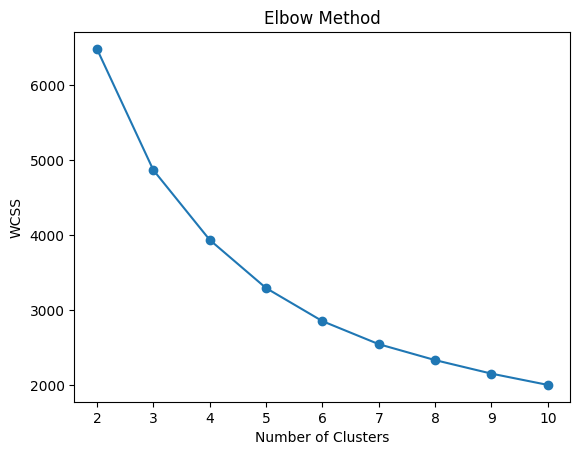

In [73]:
wcss = []

for k in range(2, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(scaled_data)

    wcss.append(model.inertia_)

plt.plot(range(2, 11), wcss, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [74]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(scaled_data)

print(rfm.head())

            Recency  Frequency  Monetary  KMeans_Cluster
CustomerID                                              
12346           326          1  77183.60               3
12347             2          7   4310.00               0
12348            75          4   1797.24               3
12349            19          1   1757.55               2
12350           310          1    334.40               1


In [75]:
dbscan = DBSCAN(
    eps=0.6,
    min_samples=5
)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(scaled_data)

print(rfm['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    4300
-1      33
 1       5
Name: count, dtype: int64


In [76]:
print(
    rfm.groupby('DBSCAN_Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].mean().round(2)
)

                Recency  Frequency  Monetary
DBSCAN_Cluster                              
-1                60.82      48.06  67627.48
 0                92.88       3.88   1492.83
 1                 4.40      50.20  47269.74


In [77]:
score_kmeans = silhouette_score(
    scaled_data,
    rfm['KMeans_Cluster']
)

print("KMeans Silhouette Score:", score_kmeans)

KMeans Silhouette Score: 0.337517049212612


In [88]:
labels = rfm['DBSCAN_Cluster']
mask = labels != -1

if len(set(labels[mask])) > 1:
    score = silhouette_score(
        scaled_data[mask],
        labels[mask]
    )
    print("DBSCAN Silhouette Score:", score)

DBSCAN Silhouette Score: 0.5669710320849832


In [79]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

print(pca_data.shape)

(4338, 2)


In [80]:
rfm['PCA1'] = pca_data[:, 0]

rfm['PCA2'] = pca_data[:, 1]

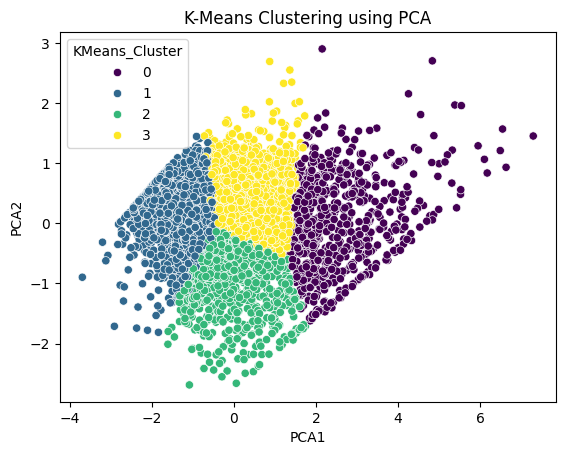

In [90]:
sns.scatterplot(
    data=rfm,
    x='PCA1',
    y='PCA2',
    hue='KMeans_Cluster',
    palette='viridis'
)

plt.title("K-Means Clustering using PCA")

plt.show()

In [82]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

tsne_data = tsne.fit_transform(scaled_data)

rfm['TSNE1'] = tsne_data[:, 0]

rfm['TSNE2'] = tsne_data[:, 1]

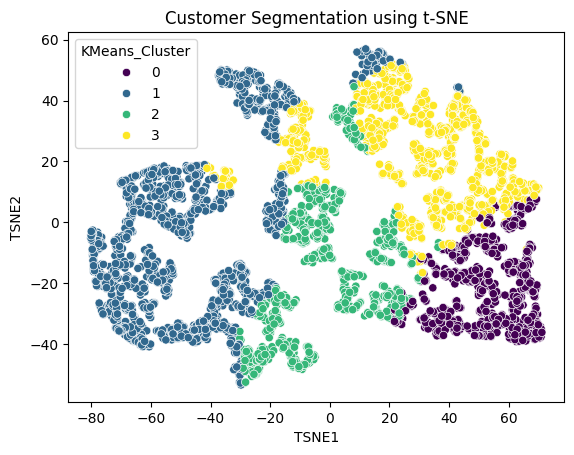

In [83]:
sns.scatterplot(
    data=rfm,
    x='TSNE1',
    y='TSNE2',
    hue='KMeans_Cluster',
    palette='viridis'
)

plt.title("Customer Segmentation using t-SNE")

plt.show()

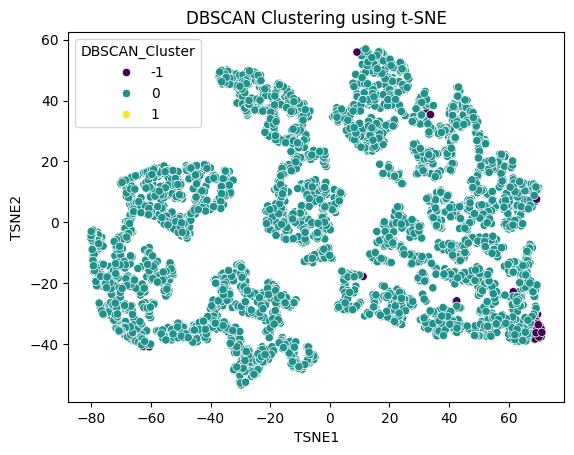

In [84]:
sns.scatterplot(
    data=rfm,
    x='TSNE1',
    y='TSNE2',
    hue='DBSCAN_Cluster',
    palette='viridis'
)

plt.title("DBSCAN Clustering using t-SNE")

plt.show()

In [91]:
personas = rfm.groupby('DBSCAN_Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

print(personas)

                  Recency  Frequency      Monetary
DBSCAN_Cluster                                    
-1              60.818182  48.060606  67627.483939
 0              92.882326   3.882558   1492.826331
 1               4.400000  50.200000  47269.740000
